# [VERSÃO 4] Módulos de Explicabilidade — Grad-CAM++, LIME e SHAP

Este notebook aplica três técnicas de explicabilidade — **Grad-CAM++**,
**LIME** e **SHAP** — ao modelo de classificação de tumores cerebrais
treinado no pipeline `[VERSAO_8]_Modelo_Desvio_Hiperparametro` (validação
cruzada estratificada, 5 seeds x 5 folds), além de uma avaliação
quantitativa das explicações com os índices de **Gini** e **AOPC**.

## Alinhamento com a Versão 8 do modelo
- **Pastas**: ler o `resultados_cv/execucoes.json` e os modelos em
  `modelos_salvos_cv/`.
- **Identificação do modelo**: cada execução é um par **(seed, fold)**.
  Por padrão é carregada a de melhor F1; é possível escolher manualmente
  (`SEED_ESCOLHIDA` / `FOLD_ESCOLHIDO`).
- **Banco de imagens**: por padrão é sorteado **somente entre as imagens de
  TESTE do fold** do modelo carregado (arquivos `test_paths_seed{S}_fold{K}.npy`
  salvos pela V8). Assim, Gini/AOPC nunca são calculados em imagens que o
  modelo viu no treino/validação (evita vazamento de dados).
- **Pré-processamento idêntico ao do treino**: `carregar_e_segmentar` agora
  reproduz exatamente o que a V8 fez (`cv2.resize` -> segmentação -> salvar
  com a extensão original da imagem -> decodificar).
- **Resultados separados por modelo**: as saídas vão para
  `explicabilidade_cv/seed{S}_fold{K}/`, sem misturar métricas de modelos
  diferentes nem sobrescrever os resultados das versões anteriores.
- `salvar_metrica` agora grava `seed` e `fold` em cada registro.

O notebook é organizado em **módulos independentes**, cada um com suas
próprias importações e configuração, de modo que seja possível rodar apenas
o módulo necessário (Grad-CAM++, LIME ou SHAP) sem depender dos outros.

## Estrutura do notebook
- **Módulo 0** — Configuração compartilhada (rodar sempre primeiro): mount do
  Drive, download do dataset, escolha e carregamento do modelo (seed + fold),
  pré-processamento idêntico ao treino e montagem do banco de imagens.
- **Módulo 1** — Grad-CAM++
- **Módulo 2** — LIME
- **Módulo 3** — SHAP
- **Módulo 4** — Avaliação Quantitativa (Índice de Gini e AOPC)

# Módulo 0 — Configuração Compartilhada

**Rode esta célula sempre que abrir o notebook ou reiniciar a sessão.**

Pré-requisito: a pasta `resultados_cv/` (com `execucoes.json` e os
`test_paths_*.npy` / `test_labels_*.npy`) e a pasta `modelos_salvos_cv/`
geradas pela Versão 8 do modelo precisam estar no Drive.

In [ ]:
# --------------------------------------------------------------
# 0.1. Mount do Google Drive
# --------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

# --------------------------------------------------------------
# 0.2. Importações gerais deste módulo
# --------------------------------------------------------------
import os
import json
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import kagglehub

# --------------------------------------------------------------
# 0.3. Caminhos do projeto  [V4] alinhados à estrutura da V8 do modelo
#      (a V8 grava tudo da validação cruzada em `*_cv`)
# --------------------------------------------------------------
BASE_DIR = '/content/drive/MyDrive/Projeto/Desv_Hip'
RUN_DIR = os.path.join(BASE_DIR, '224x224')
CV_DIR = os.path.join(RUN_DIR, 'resultados_cv')            # execucoes.json, test_paths_*.npy, ...
MODELOS_DIR = os.path.join(RUN_DIR, 'modelos_salvos_cv')   # Desv_Hip_224_seed{S}_fold{K}.keras
RESULTS_PATH = os.path.join(CV_DIR, 'execucoes.json')

IMAGE_SIZE = (224, 224)  # precisa bater com o IMAGE_SIZE do treino (V8, bloco 2.1)

# --------------------------------------------------------------
# 0.4. Download do dataset (mesmo dataset e mesma varredura do treino)
# --------------------------------------------------------------
dataset_path = kagglehub.dataset_download("mohammadhossein77/brain-tumors-dataset")
print("Caminho do dataset:", dataset_path)

valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
image_paths_full = []
labels_raw_full = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(valid_extensions):
            image_paths_full.append(os.path.join(root, file))
            labels_raw_full.append(os.path.basename(root))

# Nomes de classe descobertos dinamicamente (igual ao treino).
class_names_list = sorted(list(set(labels_raw_full)))
num_classes = len(class_names_list)
class_to_label = {name: i for i, name in enumerate(class_names_list)}
label_to_class = {i: name for name, i in class_to_label.items()}

print(f"\nClasses identificadas ({num_classes}): {class_names_list}")
for name, idx in class_to_label.items():
    count = labels_raw_full.count(name)
    print(f" - {idx}: {name} ({count} imagens)")

# [V4] A V8 treinou com imagens pré-segmentadas salvas em
# /content/dataset_segmentado, com nome "achatado" (caminho relativo ao dataset,
# com os separadores trocados por "_"). Esse diretório some quando a sessão do
# Colab reinicia, mas os `test_paths_*.npy` guardam esses caminhos. Este mapa
# permite voltar do nome achatado para a imagem ORIGINAL no dataset.
mapa_flat_para_original = {
    os.path.relpath(p, dataset_path).replace(os.sep, '_'): p for p in image_paths_full
}

# --------------------------------------------------------------
# 0.5. [V4] Escolher e carregar o modelo (seed + fold da validação cruzada)
#      - Padrão: execução com MELHOR F1 dentre as 25 (5 seeds x 5 folds).
#      - Para usar uma execução específica, preencha SEED_ESCOLHIDA e
#        FOLD_ESCOLHIDO (ex.: 42 e 0). Deixe ambos None para o melhor F1.
# --------------------------------------------------------------
SEED_ESCOLHIDA = None
FOLD_ESCOLHIDO = None

with open(RESULTS_PATH, 'r') as f:
    resultados = json.load(f)
print(f"\nexecucoes.json: {len(resultados)} execuções (seed x fold) registradas.")

if SEED_ESCOLHIDA is None or FOLD_ESCOLHIDO is None:
    melhor_execucao = max(resultados, key=lambda r: r['f1'])
else:
    melhor_execucao = next(
        (r for r in resultados if r['seed'] == SEED_ESCOLHIDA and r['fold'] == FOLD_ESCOLHIDO), None
    )
    if melhor_execucao is None:
        raise ValueError(f"Execução seed={SEED_ESCOLHIDA} | fold={FOLD_ESCOLHIDO} "
                         f"não encontrada em {RESULTS_PATH}.")

SEED_MODELO = melhor_execucao['seed']
FOLD_MODELO = melhor_execucao['fold']
SUFIXO_MODELO = f"seed{SEED_MODELO}_fold{FOLD_MODELO}"

# Prefere reconstruir o caminho a partir de MODELOS_DIR (funciona mesmo que o
# Drive seja montado em outro lugar); cai para o caminho gravado no JSON.
modelo_path = os.path.join(MODELOS_DIR, f"Desv_Hip_224_{SUFIXO_MODELO}.keras")
if not os.path.exists(modelo_path):
    modelo_path = melhor_execucao['modelo_path']
if not os.path.exists(modelo_path):
    raise FileNotFoundError(f"Modelo da execução {SUFIXO_MODELO} não encontrado em {modelo_path}")

print(f"\nCarregando modelo seed={SEED_MODELO} | fold={FOLD_MODELO} "
      f"(F1={melhor_execucao['f1']:.4f} | acc={melhor_execucao['accuracy']:.4f}) de:\n{modelo_path}")

model = keras.models.load_model(modelo_path)
assert model.output_shape[-1] == num_classes, (
    f"O modelo tem {model.output_shape[-1]} saídas, mas o dataset tem {num_classes} classes.")
print("Modelo carregado com sucesso.")

# [V4] Pasta própria de explicabilidade POR MODELO (seed/fold), para não misturar
# métricas de modelos diferentes nem sobrescrever os resultados das versões anteriores.
EXPLICABILIDADE_DIR = os.path.join(RUN_DIR, 'explicabilidade_cv', SUFIXO_MODELO)
os.makedirs(EXPLICABILIDADE_DIR, exist_ok=True)
print(f"Resultados de explicabilidade serão salvos em: {EXPLICABILIDADE_DIR}")

# --------------------------------------------------------------
# 0.6. Função de segmentação (idêntica à da V8, bloco 1.5.1)
# --------------------------------------------------------------
def segment_image_cv(image_tensor):
    """
    Otsu (separa objeto do fundo por intensidade) + maior componente
    conectado (remove ruído solto) + convex hull preenchido (evita que um
    tumor com brilho parecido com o fundo vire um "buraco" na máscara).
    """
    img = image_tensor.numpy().astype(np.uint8) if hasattr(image_tensor, 'numpy') else image_tensor.astype(np.uint8)
    if len(img.shape) == 4:
        img = np.squeeze(img, axis=0)

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (7, 7), 0)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    n_labels, labels_img, stats, _ = cv2.connectedComponentsWithStats(thresh, connectivity=8)
    if n_labels > 1:  # label 0 é sempre o fundo
        maior_componente = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        thresh = np.where(labels_img == maior_componente, 255, 0).astype(np.uint8)

    contornos, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contornos:
        maior_contorno = max(contornos, key=cv2.contourArea)
        hull = cv2.convexHull(maior_contorno)
        thresh_hull = np.zeros_like(thresh)
        cv2.drawContours(thresh_hull, [hull], -1, 255, thickness=cv2.FILLED)
        thresh = thresh_hull

    segmented = cv2.bitwise_and(img, img, mask=thresh)
    return segmented.astype(np.float32)


def carregar_e_segmentar(img_path):
    """
    [V4] Reproduz EXATAMENTE o pré-processamento da V8 (blocos 1.5.2 e 2.6):
        cv2.imread -> RGB -> cv2.resize(224x224) -> segment_image_cv
        -> salvar em disco (cv2.imwrite, com a MESMA extensão da imagem original,
           então .jpg passa por compressão JPEG) -> tf.io.read/decode -> tf.image.resize.
    Aqui o "salvar em disco" é feito em memória (cv2.imencode), com o mesmo resultado.

    `img_path` é o caminho da imagem ORIGINAL do dataset (NÃO a já segmentada),
    portanto a segmentação é aplicada uma única vez, como no treino.
    Retorna float32 (224, 224, 3) com pixels 0-255, sem normalização — é o que a
    EfficientNetB0 do Keras espera (e o que o modelo recebeu no treino).
    """
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f"Não foi possível ler a imagem: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMAGE_SIZE)
    seg = segment_image_cv(img).astype(np.uint8)

    ext = os.path.splitext(img_path)[1].lower() or '.jpg'
    ok, buf = cv2.imencode(ext, cv2.cvtColor(seg, cv2.COLOR_RGB2BGR))
    if not ok:
        raise RuntimeError(f"Falha ao codificar a imagem segmentada ({ext}).")

    img_final = tf.io.decode_image(buf.tobytes(), channels=3, expand_animations=False)
    img_final = tf.image.resize(img_final, IMAGE_SIZE)
    return img_final.numpy().astype(np.float32)


# --------------------------------------------------------------
# 0.7. Função de predição padrão (usada pelo LIME, SHAP e AOPC)
# --------------------------------------------------------------
def predict_fn(images):
    return model.predict(images, verbose=0)

# --------------------------------------------------------------
# 0.8. Banco de imagens de exemplo
#      [V4] MODO_BANCO:
#        'teste_fold'       -> (padrão) sorteia somente entre as imagens de TESTE
#                              do fold deste modelo (test_paths_seed{S}_fold{K}.npy),
#                              isto é, imagens que o modelo NUNCA viu no treino/validação.
#        'dataset_completo' -> sorteia no dataset inteiro (comportamento da V3;
#                              pode incluir imagens de treino deste modelo).
# --------------------------------------------------------------
MODO_BANCO = 'teste_fold'
N_POR_CLASSE = 5

def montar_banco_imagens(n_por_classe=5, seed=42, modo=MODO_BANCO):
    rng = np.random.default_rng(seed)

    if modo == 'teste_fold':
        test_paths = np.load(os.path.join(CV_DIR, f'test_paths_{SUFIXO_MODELO}.npy'))
        test_labels = np.load(os.path.join(CV_DIR, f'test_labels_{SUFIXO_MODELO}.npy'))

        candidatos = {classe: [] for classe in class_names_list}
        nao_encontradas = 0
        for p, lbl in zip(test_paths, test_labels):
            original = mapa_flat_para_original.get(os.path.basename(str(p)))
            if original is None:
                nao_encontradas += 1
                continue
            candidatos[label_to_class[int(lbl)]].append(original)
        if nao_encontradas:
            raise RuntimeError(f"{nao_encontradas} imagens de teste do fold não foram "
                               f"encontradas no dataset baixado. Confira a versão do dataset.")
        print(f"\nPool de TESTE do fold ({SUFIXO_MODELO}): {len(test_paths)} imagens")
    elif modo == 'dataset_completo':
        labels_raw_arr = np.array(labels_raw_full)
        candidatos = {
            classe: [image_paths_full[i] for i in np.where(labels_raw_arr == classe)[0]]
            for classe in class_names_list
        }
        print("\nAVISO: modo 'dataset_completo' — o banco pode incluir imagens usadas no "
              "treino/validação deste modelo.")
    else:
        raise ValueError("MODO_BANCO deve ser 'teste_fold' ou 'dataset_completo'.")

    banco = {}
    for classe in class_names_list:
        pool = candidatos[classe]
        n = min(n_por_classe, len(pool))
        escolhidos = rng.choice(len(pool), size=n, replace=False)
        banco[classe] = [pool[i] for i in escolhidos]
    return banco

banco_imagens = montar_banco_imagens(n_por_classe=N_POR_CLASSE)

print("\nBanco de imagens de exemplo:")
for classe, imgs in banco_imagens.items():
    print(f" - {classe}: {len(imgs)} imagens")

# --------------------------------------------------------------
# 0.8b. Conferência rápida (sanidade do pipeline): o modelo deve acertar a
#       grande maioria do banco de teste. Se a acurácia vier muito baixa,
#       algo no pré-processamento/ordem de classes está desalinhado do treino.
# --------------------------------------------------------------
acertos, total = 0, 0
for classe, imgs in banco_imagens.items():
    if not imgs:
        continue
    lote = np.array([carregar_e_segmentar(p) for p in imgs])
    pred = np.argmax(predict_fn(lote), axis=1)
    ac = int(np.sum(pred == class_to_label[classe]))
    acertos += ac
    total += len(imgs)
    print(f"   {classe}: {ac}/{len(imgs)} corretas")
print(f"Acurácia do modelo no banco de exemplo: {acertos}/{total} "
      f"(acurácia no teste do fold registrada na V8: {melhor_execucao['accuracy']:.4f})")

print("\nMódulo 0 concluído — configuração compartilhada pronta.")

Mounted at /content/drive


100%|██████████| 221M/221M [00:06<00:00, 34.6MB/s]

Extracting files...


Caminho do dataset: /root/.cache/kagglehub/datasets/mohammadhossein77/brain-tumors-dataset/versions/3

Classes identificadas (4): ['Normal', 'glioma_tumor', 'meningioma_tumor', 'pituitary_tumor']
 - 0: Normal (3066 imagens)
 - 1: glioma_tumor (6307 imagens)
 - 2: meningioma_tumor (6391 imagens)
 - 3: pituitary_tumor (5908 imagens)

execucoes.json: 25 execuções (seed x fold) registradas.

Carregando modelo seed=7 | fold=3 (F1=0.9855 | acc=0.9855) de:
/content/drive/MyDrive/Projeto/Desv_Hip/224x224/modelos_salvos_cv/Desv_Hip_224_seed7_fold3.keras
Modelo carregado com sucesso.
Resultados de explicabilidade serão salvos em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3

Pool de TESTE do fold (seed7_fold3): 4334 imagens

Banco de imagens de exemplo:
 - Normal: 5 imagens
 - glioma_tumor: 5 imagens
 - meningioma_tumor: 5 imagens
 - pituitary_tumor: 5 imagens
   Normal: 5/5 corretas
   glioma_tumor: 5/5 corretas
   meningioma_tumor: 5/5 corretas
   pituitary_tu

In [ ]:
# --------------------------------------------------------------
# 0.9. Índice de Gini (concentração da explicação)
# --------------------------------------------------------------
def gini_index(importance_values):
    """Mede o quão concentrada (vs. espalhada) está a importância atribuída
    pela técnica de XAI. 0 = importância uniforme por toda a imagem,
    1 = toda a importância concentrada em poucos pixels/regiões."""
    valores = np.abs(np.asarray(importance_values, dtype=np.float64)).flatten()
    valores = np.sort(valores)
    n = len(valores)
    soma = valores.sum()
    if soma == 0 or n == 0:
        return 0.0
    cum = np.cumsum(valores)
    return float((n + 1 - 2 * np.sum(cum) / cum[-1]) / n)

# --------------------------------------------------------------
# 0.10. AOPC (Area Over the Perturbation Curve)
# --------------------------------------------------------------
def calcular_aopc(img_segmented, importance_map, target_class_idx,
                   n_segmentos=20, n_steps=10, valor_perturbacao=None):
    """
    Mede o quanto a probabilidade da classe alvo cai a medida que as
    regioes mais "importantes" (segundo a tecnica de XAI) vao sendo
    apagadas da imagem, uma a uma. Quanto MAIOR o AOPC, mais a tecnica
    esta apontando corretamente para regioes que o modelo realmente usa.

    - img_segmented: imagem (H, W, 3), 0-255, ja segmentada (saida de
      carregar_e_segmentar).
    - importance_map: mapa de importancia (H, W) ja redimensionado para o
      tamanho da imagem (heatmap do Grad-CAM++, |SHAP| por pixel, etc).
    - target_class_idx: indice da classe cuja probabilidade sera
      monitorada (normalmente a classe predita).
    - n_segmentos: em quantos blocos a imagem e dividida via SLIC para a
      perturbacao progressiva.
    - n_steps: quantos desses blocos (do mais importante ao menos
      importante) sao efetivamente removidos, um por um.
    """
    from skimage.segmentation import slic

    img = img_segmented.astype(np.float64)
    segments = slic(img.astype(np.uint8), n_segments=n_segmentos,
                     compactness=10, sigma=1, start_label=0)

    importancia_por_segmento = []
    for s in np.unique(segments):
        mask = segments == s
        importancia_por_segmento.append((s, importance_map[mask].mean()))
    importancia_por_segmento.sort(key=lambda x: x[1], reverse=True)

    n_steps = min(n_steps, len(importancia_por_segmento))
    valor_base = img.mean(axis=(0, 1)) if valor_perturbacao is None else valor_perturbacao

    img_perturbada = img.copy()
    prob_inicial = float(predict_fn(np.expand_dims(img, axis=0))[0, target_class_idx])

    quedas = []
    for k in range(n_steps):
        seg_id, _ = importancia_por_segmento[k]
        mask = segments == seg_id
        img_perturbada[mask] = valor_base
        prob_k = float(predict_fn(np.expand_dims(img_perturbada, axis=0))[0, target_class_idx])
        quedas.append(prob_inicial - prob_k)

    return float(np.mean(quedas)) if quedas else 0.0


# --------------------------------------------------------------
# 0.11. Arquivo de resultados acumulado (persiste no Drive entre sessoes,
#       entao funciona mesmo rodando os modulos em dias/sessoes diferentes)
# --------------------------------------------------------------
METRICAS_DIR = os.path.join(EXPLICABILIDADE_DIR, 'metricas')
os.makedirs(METRICAS_DIR, exist_ok=True)
METRICAS_PATH = os.path.join(METRICAS_DIR, 'resultados_metricas.json')

def carregar_metricas():
    if os.path.exists(METRICAS_PATH):
        with open(METRICAS_PATH, 'r') as f:
            return json.load(f)
    return []

def salvar_metrica(tecnica, classe, arquivo, gini, aopc, extra=None):
    registros = carregar_metricas()
    registro = {
        'tecnica': tecnica,
        'classe': classe,
        'arquivo': arquivo,
        'gini': gini,
        'aopc': aopc,
        'seed': SEED_MODELO,   # [V4] rastreia qual modelo (seed/fold) gerou a métrica
        'fold': FOLD_MODELO,
        'modo_banco': MODO_BANCO,
    }
    if extra:
        registro.update(extra)
    # substitui um registro existente da mesma (tecnica, classe, arquivo), se houver
    registros = [r for r in registros if not (
        r['tecnica'] == tecnica and r['classe'] == classe and r['arquivo'] == arquivo
    )]
    registros.append(registro)
    with open(METRICAS_PATH, 'w') as f:
        json.dump(registros, f, indent=2, ensure_ascii=False)
    return registro

print("Modulo 0.9-0.11 concluido - funcoes de Gini/AOPC e arquivo de metricas prontos.")
print(f"Resultados serao acumulados em: {METRICAS_PATH}")


Modulo 0.9-0.11 concluido - funcoes de Gini/AOPC e arquivo de metricas prontos.
Resultados serao acumulados em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/metricas/resultados_metricas.json


# Módulo 1 — Grad-CAM++

Requer o **Módulo 0** já executado nesta sessão. Gera mapas de calor
mostrando quais regiões da imagem mais influenciaram a predição do modelo.


### 1.1 Importações e preparação dos sub-modelos (rodar 1x por sessão)

In [ ]:
# --------------------------------------------------------------
# Importações específicas deste módulo
# --------------------------------------------------------------
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import os

# --------------------------------------------------------------
# 1.1. Localizar a sub-rede EfficientNetB0 dentro do modelo treinado
#      Procura dinamicamente por qualquer camada cujo nome contenha
#      'efficientnet', mais robusto a mudanças de nomenclatura entre versões
#      do Keras/TensorFlow.
# --------------------------------------------------------------
inner_model = None
for layer in model.layers:
    if 'efficientnet' in layer.name.lower():
        inner_model = layer
        break

if inner_model is None:
    raise ValueError("Não foi possível localizar a EfficientNetB0 dentro do "
                      "modelo. Confira model.summary().")

print(f"Sub-rede encontrada: '{inner_model.name}'")

target_layer_name = 'top_activation'  # padrão do EfficientNet (última feature map antes do pooling)
target_layer = inner_model.get_layer(target_layer_name)
print(f"Camada alvo do Grad-CAM++: '{target_layer_name}' -> saída {target_layer.output.shape}")

# --------------------------------------------------------------
# 1.2. Criar o extrator de features (até a última conv) e o classificador
#      (o restante do modelo, após a EfficientNetB0)
# --------------------------------------------------------------
last_conv_model = tf.keras.Model(inputs=inner_model.input, outputs=target_layer.output)

classifier_input = tf.keras.Input(shape=target_layer.output.shape[1:])
x = classifier_input
eff_layer_index = model.layers.index(inner_model)
for layer in model.layers[eff_layer_index + 1:]:
    x = layer(x)
classifier_model = tf.keras.Model(inputs=classifier_input, outputs=x)

print(f"Extrator de Features: {last_conv_model.input.shape} -> {last_conv_model.output.shape}")
print(f"Classificador: {classifier_model.input.shape} -> {classifier_model.output.shape}")

# --------------------------------------------------------------
# 1.3. Função Grad-CAM++
# --------------------------------------------------------------
def gerar_gradcam_plus_plus(img_path):
    img_segmented = carregar_e_segmentar(img_path)
    img_batch = np.expand_dims(img_segmented, axis=0)

    with tf.GradientTape() as tape_1:
        with tf.GradientTape() as tape_2:
            with tf.GradientTape() as tape_3:
                conv_outputs = last_conv_model(img_batch)
                predictions = classifier_model(conv_outputs)
                best_class_index = tf.argmax(predictions[0])
                loss = predictions[:, best_class_index]
            first_grads = tape_3.gradient(loss, conv_outputs)
        second_grads = tape_2.gradient(first_grads, conv_outputs)
    third_grads = tape_1.gradient(second_grads, conv_outputs)

    global_sum = np.sum(conv_outputs, axis=(0, 1, 2))
    alpha_num = second_grads[0]
    alpha_denom = 2.0 * second_grads[0] + global_sum * third_grads[0]
    alpha_denom = np.where(alpha_denom != 0.0, alpha_denom, 1e-10)

    alphas = alpha_num / alpha_denom
    alphas_norm = np.sum(alphas, axis=(0, 1))
    alphas_norm = np.where(alphas_norm != 0.0, alphas_norm, 1e-10)
    alphas /= alphas_norm

    weights = np.maximum(first_grads[0], 0.0)
    deep_linearization_weights = np.sum(weights * alphas, axis=(0, 1))

    heatmap = np.sum(conv_outputs[0] * deep_linearization_weights, axis=-1)
    heatmap = np.maximum(heatmap, 0)  # ReLU
    if np.max(heatmap) != 0:
        heatmap /= np.max(heatmap)  # normaliza para 0-1

    return heatmap, img_segmented, int(best_class_index.numpy())

print("\nFerramentas do Grad-CAM++ prontas.")


Sub-rede encontrada: 'efficientnetb0'
Camada alvo do Grad-CAM++: 'top_activation' -> saída (None, 7, 7, 1280)
Extrator de Features: (None, 224, 224, 3) -> (None, 7, 7, 1280)
Classificador: (None, 7, 7, 1280) -> (None, 4)

Ferramentas do Grad-CAM++ prontas.


### 1.2 Execução do Grad-CAM++ por classe

* Mude `CLASSE_ALVO` para o nome da classe desejada (veja `class_names_list` no Módulo 0).

--- Processando Grad-CAM++ para: pituitary_tumor ---
[1/5] Gerando para: P_732_BR_.jpg...


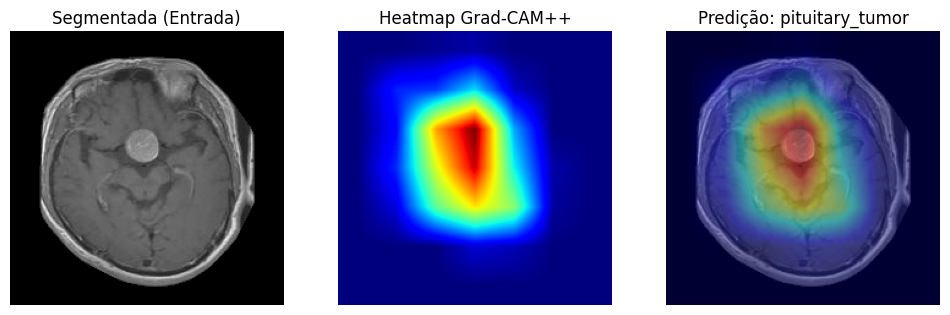

    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/GradCAM/pituitary_tumor/GradCAM_P_732_BR_.jpg
[2/5] Gerando para: P_402_RO_.jpg...


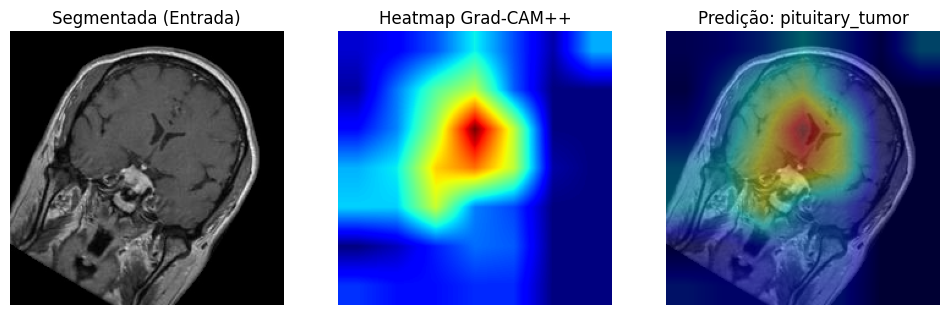

    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/GradCAM/pituitary_tumor/GradCAM_P_402_RO_.jpg
[3/5] Gerando para: P_9_HF_.jpg...


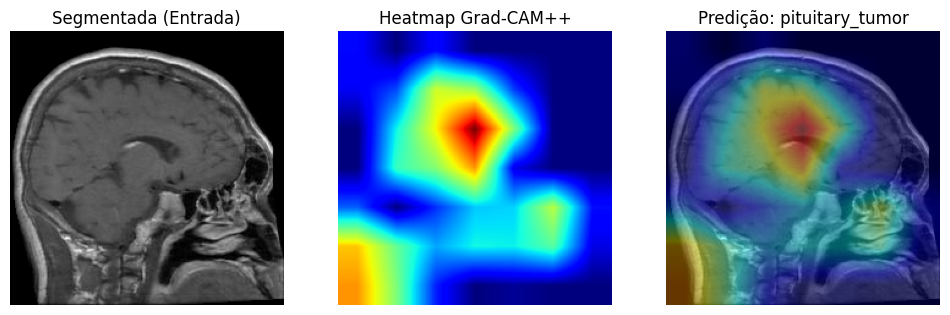

    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/GradCAM/pituitary_tumor/GradCAM_P_9_HF_.jpg
[4/5] Gerando para: P_210_VF_.jpg...


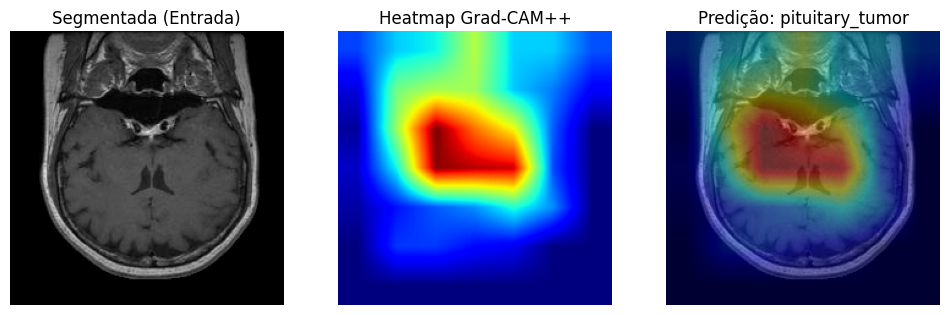

    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/GradCAM/pituitary_tumor/GradCAM_P_210_VF_.jpg
[5/5] Gerando para: P_636_DA_.jpg...


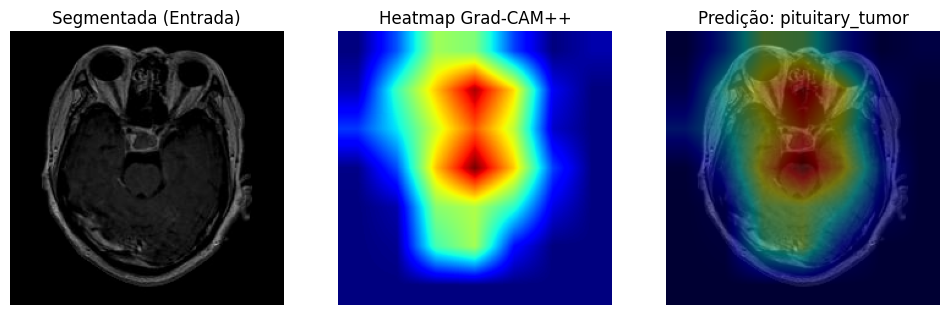

    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/GradCAM/pituitary_tumor/GradCAM_P_636_DA_.jpg

pituitary_tumor concluído.


In [ ]:
# ==========================================
# - 0: Normal
# - 1: glioma_tumor
# - 2: meningioma_tumor
# - 3: pituitary_tumor
# ==========================================
CLASSE_ALVO = class_names_list[3]
# ==========================================

output_folder = os.path.join(EXPLICABILIDADE_DIR, 'GradCAM', CLASSE_ALVO)
os.makedirs(output_folder, exist_ok=True)

print(f"--- Processando Grad-CAM++ para: {CLASSE_ALVO} ---")

lista_imgs = banco_imagens[CLASSE_ALVO]

for i, img_path in enumerate(lista_imgs):
    filename = os.path.basename(img_path)
    print(f"[{i+1}/{len(lista_imgs)}] Gerando para: {filename}...")

    try:
        heatmap, img_seg, pred_idx = gerar_gradcam_plus_plus(img_path)
        pred_classe = label_to_class[pred_idx]

        # --- VISUALIZAÇÃO ---
        heatmap_resized = cv2.resize(heatmap, IMAGE_SIZE)
        heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
        heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

        img_seg_uint8 = img_seg.astype(np.uint8)
        superimposed = (img_seg_uint8 * 0.6 + heatmap_colored * 0.4).astype(np.uint8)

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.title("Segmentada (Entrada)")
        plt.imshow(img_seg_uint8)
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.title("Heatmap Grad-CAM++")
        plt.imshow(heatmap_resized, cmap='jet')
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.title(f"Predição: {pred_classe}")
        plt.imshow(superimposed)
        plt.axis('off')

        save_path = os.path.join(output_folder, f"GradCAM_{filename}")
        plt.savefig(save_path, bbox_inches='tight', dpi=150)
        plt.show()
        plt.close()

        print(f"    -> Salvo em: {save_path}")

    except Exception as e:
        print(f"    -> ERRO em {filename}: {e}")

print(f"\n{CLASSE_ALVO} concluído.")



### 1.3 Avaliação — Grad-CAM++


In [ ]:
# ==========================================
# - 0: Normal
# - 1: glioma_tumor
# - 2: meningioma_tumor
# - 3: pituitary_tumor
# ==========================================
CLASSE_ALVO = class_names_list[3]

lista_imgs = banco_imagens[CLASSE_ALVO]
print(f"--- Avaliando Grad-CAM++ (Gini/AOPC) para: {CLASSE_ALVO} ---")

for i, img_path in enumerate(lista_imgs):
    filename = os.path.basename(img_path)
    print(f"[{i+1}/{len(lista_imgs)}] {filename}...")
    try:
        heatmap, img_seg, pred_idx = gerar_gradcam_plus_plus(img_path)
        heatmap_resized = cv2.resize(heatmap, IMAGE_SIZE)

        gini = gini_index(heatmap_resized)
        aopc = calcular_aopc(img_seg, heatmap_resized, pred_idx)

        salvar_metrica('GradCAM++', CLASSE_ALVO, filename, gini, aopc,
                        extra={'classe_predita': label_to_class[pred_idx]})
        print(f"    -> Gini={gini:.4f} | AOPC={aopc:.4f}")
    except Exception as e:
        print(f"    -> ERRO em {filename}: {e}")

print(f"\n{CLASSE_ALVO} (Grad-CAM++) avaliado. Resultados salvos em {METRICAS_PATH}")


--- Avaliando Grad-CAM++ (Gini/AOPC) para: pituitary_tumor ---
[1/5] P_732_BR_.jpg...
    -> Gini=0.7362 | AOPC=0.6603
[2/5] P_402_RO_.jpg...
    -> Gini=0.4928 | AOPC=0.6360
[3/5] P_9_HF_.jpg...
    -> Gini=0.5029 | AOPC=0.3058
[4/5] P_210_VF_.jpg...
    -> Gini=0.5226 | AOPC=0.5509
[5/5] P_636_DA_.jpg...
    -> Gini=0.5773 | AOPC=0.1173

pituitary_tumor (Grad-CAM++) avaliado. Resultados salvos em /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/metricas/resultados_metricas.json


# Módulo 2 — LIME

Requer o **Módulo 0** já executado nesta sessão. Explica a predição
perturbando "superpixels" da imagem e vendo quais deles mais afetam a saída
do modelo.


### 2.1 Instalação e importações (rodar 1x por sessão)

In [ ]:
# --------------------------------------------------------------
# Importações específicas deste módulo
# --------------------------------------------------------------
!pip install --quiet lime

import os
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries

# --------------------------------------------------------------
# 2.1. Explicador do LIME
# --------------------------------------------------------------
explainer = lime_image.LimeImageExplainer()

print("LIME configurado.")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
LIME configurado.


### 2.2 Execução do LIME por classe

* Mude `CLASSE_ALVO` para o nome da classe desejada (veja `class_names_list` no Módulo 0).
* `OPCAO_VISUAL`: `1` = Comparativo (lado a lado) | `2` = Prós/Contras (verde confirma, vermelho contradiz) | `3` = Isolamento (fundo preto, só as áreas mais importantes).
* O LIME é lento — espere ~40-60s por imagem.


--- Iniciando LIME (Opção 2) para pituitary_tumor ---
[1/5] Processando: P_732_BR_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

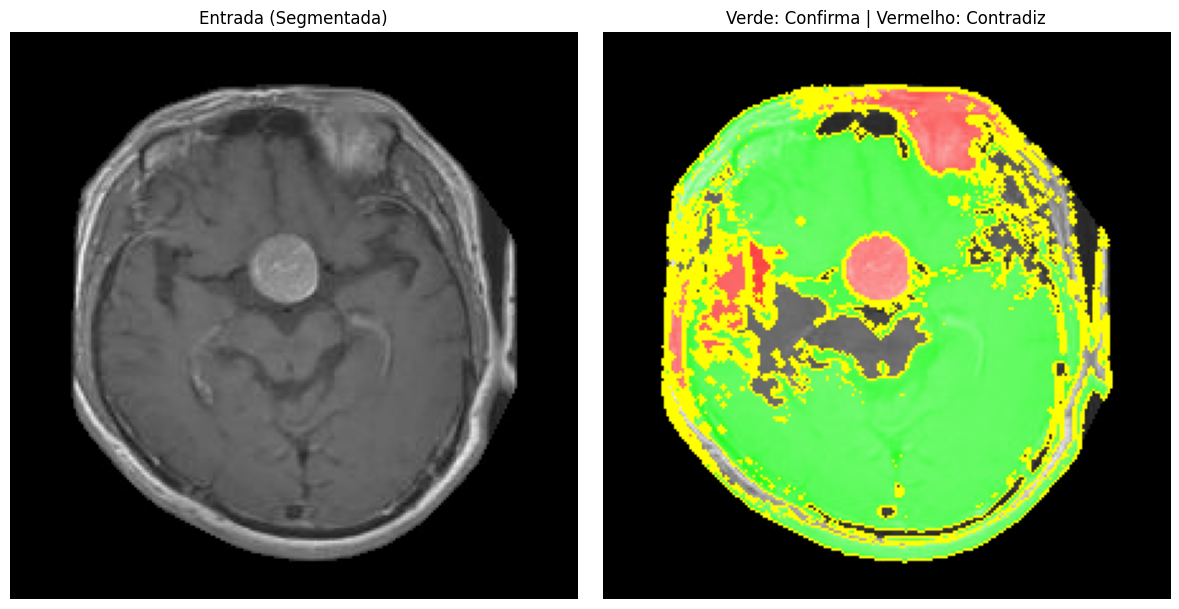

    -> Salvo: LIME_Op2_P_732_BR_.jpg
[2/5] Processando: P_402_RO_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

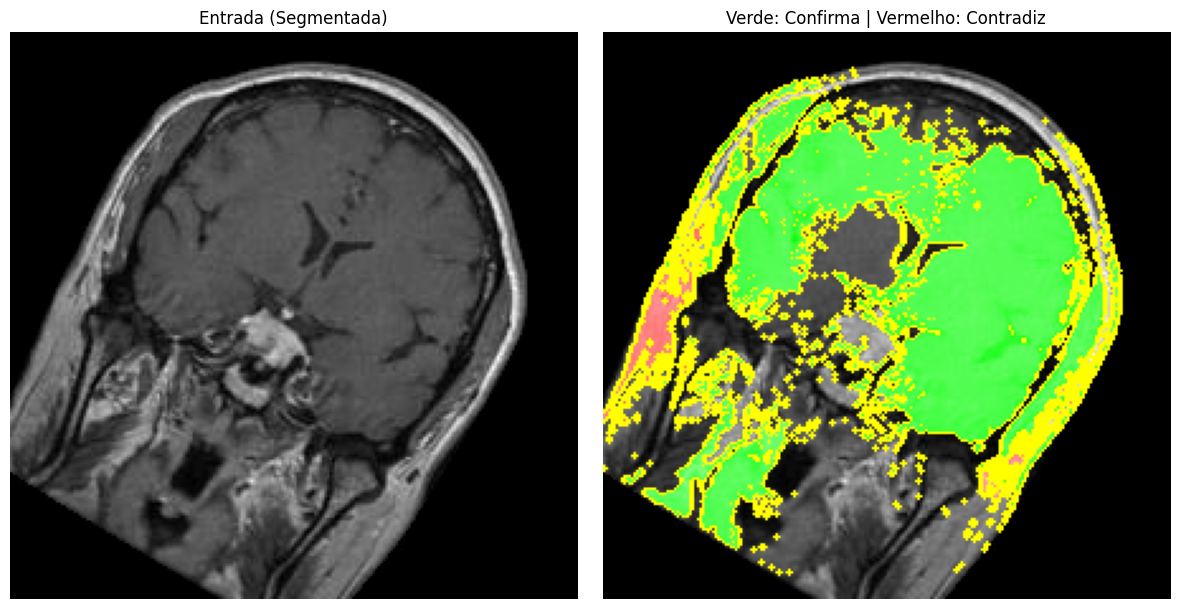

    -> Salvo: LIME_Op2_P_402_RO_.jpg
[3/5] Processando: P_9_HF_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

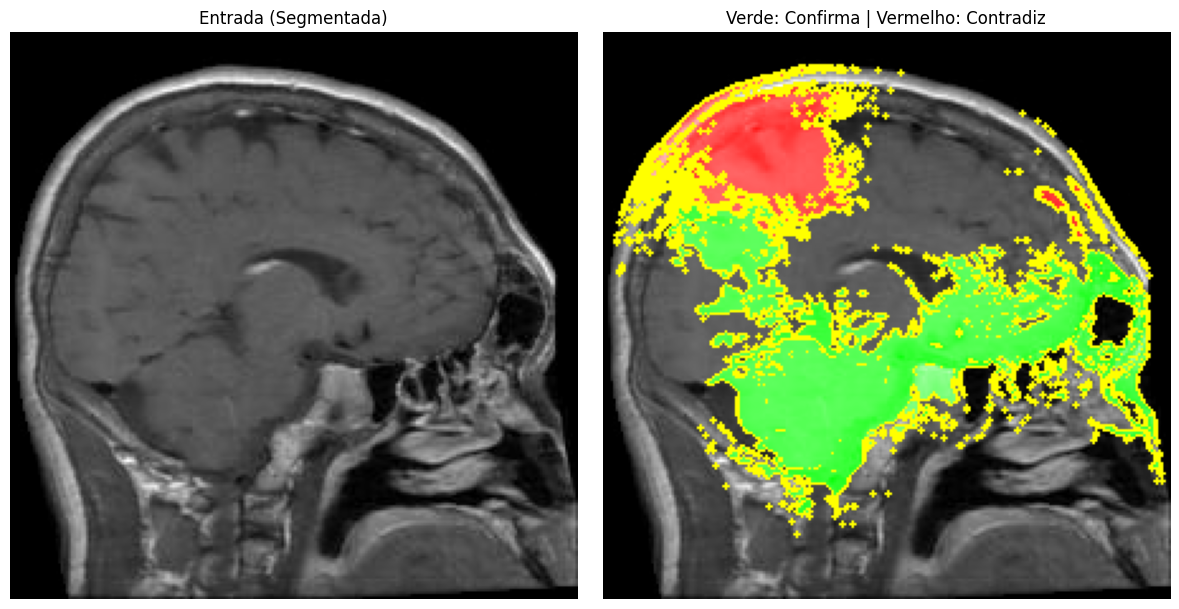

    -> Salvo: LIME_Op2_P_9_HF_.jpg
[4/5] Processando: P_210_VF_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

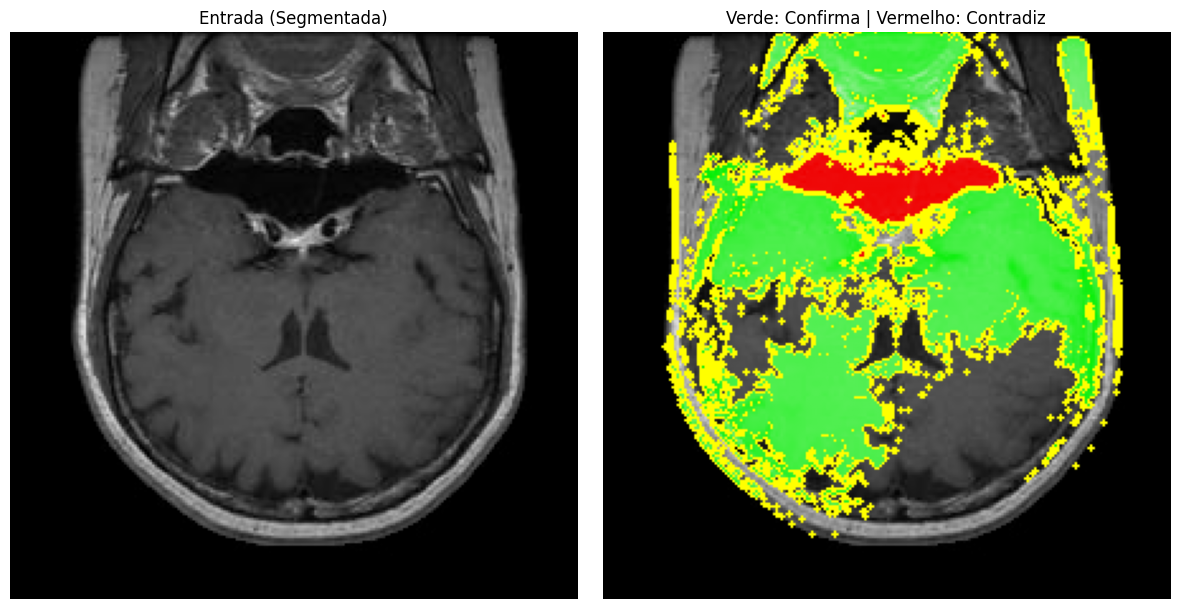

    -> Salvo: LIME_Op2_P_210_VF_.jpg
[5/5] Processando: P_636_DA_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

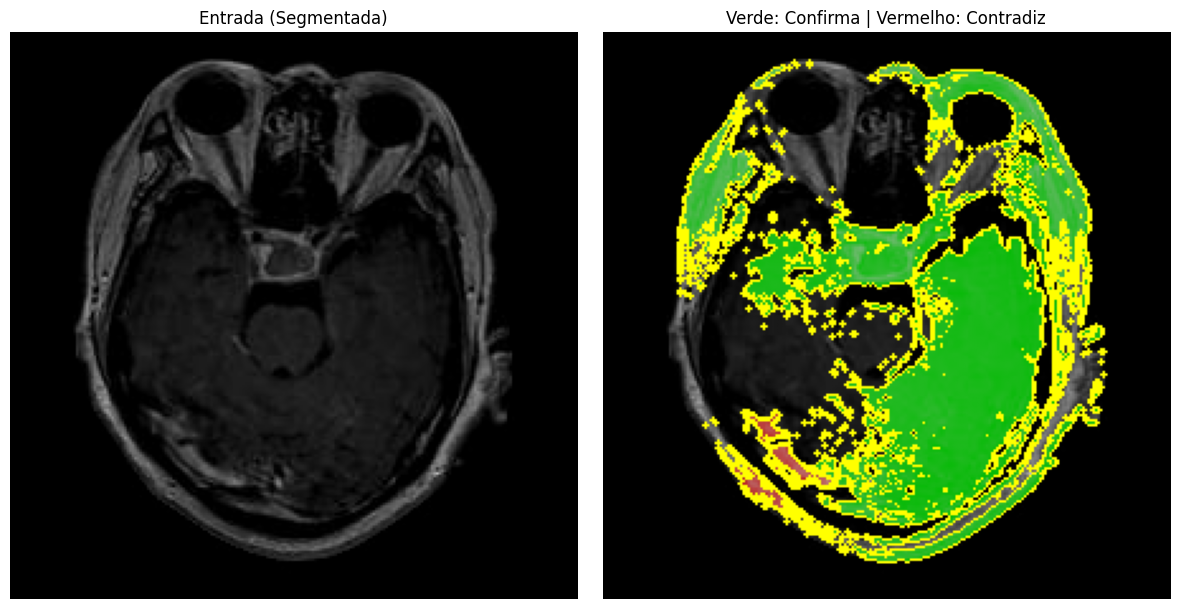

    -> Salvo: LIME_Op2_P_636_DA_.jpg

pituitary_tumor (Opção 2) concluído.


In [ ]:
# ==========================================
# - 0: Normal
# - 1: glioma_tumor
# - 2: meningioma_tumor
# - 3: pituitary_tumor
# ==========================================
CLASSE_ALVO = class_names_list[3]
OPCAO_VISUAL = 2                   # 1 = Comparativo | 2 = Prós/Contras | 3 = Isolamento
# ==========================================

def rodar_lime_em_lote(nome_classe, opcao):
    if nome_classe not in banco_imagens:
        print(f"Erro: classe '{nome_classe}' não existe no banco_imagens.")
        return

    nome_opcao = f"Opcao_{opcao}"
    output_folder = os.path.join(EXPLICABILIDADE_DIR, 'LIME', nome_classe, nome_opcao)
    os.makedirs(output_folder, exist_ok=True)

    lista_imgs = banco_imagens[nome_classe]
    print(f"--- Iniciando LIME (Opção {opcao}) para {nome_classe} ---")

    for i, img_path in enumerate(lista_imgs):
        filename = os.path.basename(img_path)
        print(f"[{i+1}/{len(lista_imgs)}] Processando: {filename}...")

        try:
            img_segmented = carregar_e_segmentar(img_path)
            img_lime = img_segmented.astype('double')

            explanation = explainer.explain_instance(
                img_lime, predict_fn, top_labels=1, hide_color=0, num_samples=1000
            )
            top_class = explanation.top_labels[0]
            top_classe_nome = label_to_class[top_class]

            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

            ax1.imshow(img_segmented.astype('uint8'))
            ax1.set_title("Entrada (Segmentada)")
            ax1.axis('off')

            if opcao == 1:  # Comparativo (foco principal)
                temp, mask = explanation.get_image_and_mask(
                    top_class, positive_only=True, num_features=5, hide_rest=False
                )
                ax2.imshow(mark_boundaries(temp / 255.0, mask))
                ax2.set_title(f"LIME: Foco Principal ({top_classe_nome})")

            elif opcao == 2:  # Prós e contras
                temp, mask = explanation.get_image_and_mask(
                    top_class, positive_only=False, num_features=8, hide_rest=False
                )
                ax2.imshow(mark_boundaries(temp / 255.0, mask))
                ax2.set_title("Verde: Confirma | Vermelho: Contradiz")

            elif opcao == 3:  # Isolamento (fundo preto)
                temp, mask = explanation.get_image_and_mask(
                    top_class, positive_only=True, num_features=5, hide_rest=True
                )
                ax2.imshow(mark_boundaries(temp / 255.0, mask))
                ax2.set_title("Apenas Áreas Vitais (Isoladas)")

            else:
                print(f"    -> Opção inválida: {opcao}. Use 1, 2 ou 3.")
                plt.close()
                continue

            ax2.axis('off')

            nome_arquivo = f"LIME_Op{opcao}_{filename}"
            save_path = os.path.join(output_folder, nome_arquivo)

            plt.tight_layout()
            plt.savefig(save_path, bbox_inches='tight', dpi=150)
            plt.show()
            plt.close()

            print(f"    -> Salvo: {nome_arquivo}")

        except Exception as e:
            print(f"    -> Erro em {filename}: {e}")

    print(f"\n{nome_classe} (Opção {opcao}) concluído.")

# --- EXECUTAR ---
rodar_lime_em_lote(CLASSE_ALVO, OPCAO_VISUAL)


### 2.3 Avaliação — LIME

In [ ]:
# ==========================================
# - 0: Normal
# - 1: glioma_tumor
# - 2: meningioma_tumor
# - 3: pituitary_tumor
# ==========================================
CLASSE_ALVO = class_names_list[3]

lista_imgs = banco_imagens[CLASSE_ALVO]
print(f"--- Avaliando LIME (Gini/AOPC) para: {CLASSE_ALVO} ---")

for i, img_path in enumerate(lista_imgs):
    filename = os.path.basename(img_path)
    print(f"[{i+1}/{len(lista_imgs)}] {filename}...")
    try:
        img_segmented = carregar_e_segmentar(img_path)
        img_lime = img_segmented.astype('double')

        explanation = explainer.explain_instance(
            img_lime, predict_fn, top_labels=1, hide_color=0, num_samples=1000
        )
        top_class = explanation.top_labels[0]

        # Reconstroi um mapa de importancia pixel-a-pixel a partir dos pesos
        # do LIME por superpixel (mesmos segmentos usados pelo LIME).
        segments = explanation.segments
        pesos = dict(explanation.local_exp[top_class])
        importance_map = np.zeros(segments.shape, dtype=np.float64)
        for seg_id, peso in pesos.items():
            importance_map[segments == seg_id] = peso
        importance_map_abs = np.abs(importance_map)

        gini = gini_index(importance_map_abs)
        aopc = calcular_aopc(img_segmented, importance_map_abs, top_class)

        salvar_metrica('LIME', CLASSE_ALVO, filename, gini, aopc,
                        extra={'classe_predita': label_to_class[top_class]})
        print(f"    -> Gini={gini:.4f} | AOPC={aopc:.4f}")
    except Exception as e:
        print(f"    -> ERRO em {filename}: {e}")

print(f"\n{CLASSE_ALVO} (LIME) avaliado. Resultados salvos em {METRICAS_PATH}")


--- Avaliando LIME (Gini/AOPC) para: pituitary_tumor ---
[1/5] P_732_BR_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

    -> Gini=0.5645 | AOPC=0.6617
[2/5] P_402_RO_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

    -> Gini=0.5962 | AOPC=0.6539
[3/5] P_9_HF_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

    -> Gini=0.5460 | AOPC=0.5043
[4/5] P_210_VF_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

    -> Gini=0.4449 | AOPC=0.5384
[5/5] P_636_DA_.jpg...


  0%|          | 0/1000 [00:00<?, ?it/s]

    -> Gini=0.7210 | AOPC=0.0553

pituitary_tumor (LIME) avaliado. Resultados salvos em /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/metricas/resultados_metricas.json


# Módulo 3 — SHAP

Requer o **Módulo 0** já executado nesta sessão. Usa a abordagem "black-box"
(`shap.Explainer` com `maskers.Image`) para atribuir, pixel a pixel, a
contribuição de cada região para cada classe.


### 3.1 Instalação e importações (rodar 1x por sessão)

In [ ]:
# --------------------------------------------------------------
# Importações específicas deste módulo
# --------------------------------------------------------------
!pip install --quiet shap

import os
import numpy as np
import shap
import matplotlib.pyplot as plt

# --------------------------------------------------------------
# 3.1. Configurar o explicador (black-box)
# --------------------------------------------------------------
masker = shap.maskers.Image(f"blur({IMAGE_SIZE[0]},{IMAGE_SIZE[1]})", (IMAGE_SIZE[0], IMAGE_SIZE[1], 3))
explainer_shap = shap.Explainer(predict_fn, masker, output_names=class_names_list)

print("SHAP configurado.")


SHAP configurado.


### 3.2 Execução do SHAP por classe

* Mude `CLASSE_ALVO` para o nome da classe desejada (veja `class_names_list` no Módulo 0).
* `max_evals=500` é um limite seguro. Para resultados mais detalhados, pode subir para 1000-2000 (mais lento).


In [ ]:
# ==========================================
# - 0: Normal
# - 1: glioma_tumor
# - 2: meningioma_tumor
# - 3: pituitary_tumor
# ==========================================
CLASSE_ALVO = class_names_list[3]
MAX_EVALS = 500
# ==========================================

output_dir = os.path.join(EXPLICABILIDADE_DIR, 'SHAP', CLASSE_ALVO)
os.makedirs(output_dir, exist_ok=True)

print(f"Iniciando geração do SHAP para a classe: {CLASSE_ALVO}")

lista_imgs = banco_imagens[CLASSE_ALVO]

for i, caminho_teste in enumerate(lista_imgs):
    nome_arquivo = os.path.basename(caminho_teste)
    print(f"[{i+1}/{len(lista_imgs)}] Processando {nome_arquivo}...")

    try:
        img_seg_teste = carregar_e_segmentar(caminho_teste)
        img_teste_batch = np.expand_dims(img_seg_teste, axis=0)

        shap_values = explainer_shap(img_teste_batch, max_evals=MAX_EVALS, batch_size=50)

        shap.image_plot(shap_values, show=False)

        fig = plt.gcf()
        fig.set_size_inches(18, 5)

        caminho_salvar = os.path.join(output_dir, f"SHAP_{nome_arquivo}.png")
        plt.savefig(caminho_salvar, bbox_inches='tight', dpi=300)
        plt.close()

        print(f"    -> Salvo em: {caminho_salvar}")

    except Exception as e:
        print(f"    -> ERRO em {nome_arquivo}: {e}")

print(f"\n{CLASSE_ALVO} concluído.")


Iniciando geração do SHAP para a classe: pituitary_tumor
[1/5] Processando P_732_BR_.jpg...


    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/SHAP/pituitary_tumor/SHAP_P_732_BR_.jpg.png
[2/5] Processando P_402_RO_.jpg...


    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/SHAP/pituitary_tumor/SHAP_P_402_RO_.jpg.png
[3/5] Processando P_9_HF_.jpg...


    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/SHAP/pituitary_tumor/SHAP_P_9_HF_.jpg.png
[4/5] Processando P_210_VF_.jpg...


    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/SHAP/pituitary_tumor/SHAP_P_210_VF_.jpg.png
[5/5] Processando P_636_DA_.jpg...


    -> Salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/SHAP/pituitary_tumor/SHAP_P_636_DA_.jpg.png

pituitary_tumor concluído.


### 3.3 Avaliação — SHAP


In [ ]:
# ==========================================
# - 0: Normal
# - 1: glioma_tumor
# - 2: meningioma_tumor
# - 3: pituitary_tumor
# ==========================================
CLASSE_ALVO = class_names_list[0]
MAX_EVALS = 500

lista_imgs = banco_imagens[CLASSE_ALVO]
print(f"--- Avaliando SHAP (Gini/AOPC) para: {CLASSE_ALVO} ---")

for i, img_path in enumerate(lista_imgs):
    filename = os.path.basename(img_path)
    print(f"[{i+1}/{len(lista_imgs)}] {filename}...")
    try:
        img_seg = carregar_e_segmentar(img_path)
        img_batch = np.expand_dims(img_seg, axis=0)

        pred = predict_fn(img_batch)[0]
        target_idx = int(np.argmax(pred))

        shap_values = explainer_shap(img_batch, max_evals=MAX_EVALS, batch_size=50)
        # shap_values.values tem forma (1, H, W, 3, n_classes) -> pega a
        # classe predita e soma os 3 canais RGB para virar um mapa (H, W)
        sv = shap_values.values[0, ..., target_idx]
        importance_map = np.abs(sv).sum(axis=-1)

        gini = gini_index(importance_map)
        aopc = calcular_aopc(img_seg, importance_map, target_idx)

        salvar_metrica('SHAP', CLASSE_ALVO, filename, gini, aopc,
                        extra={'classe_predita': label_to_class[target_idx]})
        print(f"    -> Gini={gini:.4f} | AOPC={aopc:.4f}")
    except Exception as e:
        print(f"    -> ERRO em {filename}: {e}")

print(f"\n{CLASSE_ALVO} (SHAP) avaliado. Resultados salvos em {METRICAS_PATH}")


--- Avaliando SHAP (Gini/AOPC) para: Normal ---
[1/5] N_222_HF_.jpg...
    -> Gini=0.4307 | AOPC=0.0031
[2/5] N_369_BR_.jpg...
    -> Gini=0.5003 | AOPC=0.7369
[3/5] N_47.jpg...
    -> Gini=0.4909 | AOPC=0.0754
[4/5] N_376_DA_.jpg...
    -> Gini=0.5140 | AOPC=0.3921
[5/5] N_64_SP_.jpg...
    -> Gini=0.4201 | AOPC=0.7057

Normal (SHAP) avaliado. Resultados salvos em /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/metricas/resultados_metricas.json


# Módulo 4 — Avaliação Quantitativa (Índice de Gini e AOPC)

Requer o **Módulo 0** já executado nesta sessão. Calcula duas métricas para
cada técnica de XAI (Grad-CAM++, LIME, SHAP):

- **Índice de Gini**: mede o quão *concentrada* está a importância atribuída
  pela explicação. Vai de 0 (importância espalhada por toda a imagem) a 1
  (importância concentrada em pouquíssimos pixels/regiões).
- **AOPC (Area Over the Perturbation Curve)**: mede o quanto a probabilidade
  da classe predita cai quando as regiões apontadas como mais importantes
  vão sendo apagadas, uma a uma. Quanto **maior** o AOPC, mais a explicação
  está de fato apontando para regiões que o modelo usa na decisão.

**Como isso funciona "por partes":** os resultados de cada técnica são
salvos, incrementalmente, num arquivo JSON dentro do Drive
(`explicabilidade/metricas/resultados_metricas.json`). Isso significa que
você pode rodar a avaliação do Grad-CAM++ hoje, a do LIME depois, a do SHAP
em outro dia — os resultados vão se acumulando nesse arquivo. O relatório
final pode ser rodado a qualquer momento e sempre mostra tudo
o que já foi calculado até ali, mesmo que incompleto.

O arquivo de métricas é por modelo (`explicabilidade_cv/seed{S}_fold{K}/metricas/`). Trocar `SEED_ESCOLHIDA`/`FOLD_ESCOLHIDO` no Módulo 0 começa um arquivo novo, sem misturar com o de outro modelo.

### 4.1 Relatório consolidado

Pode ser rodado a qualquer momento — só precisa do **Módulo 0** nesta sessão. Mostra tudo o que já foi calculado até este
ponto, mesmo que ainda faltem técnicas ou classes.

In [ ]:
import pandas as pd

registros = carregar_metricas()
if not registros:
    print("Nenhuma metrica calculada ainda. Rode as celulas de avaliacao 1.3, 2.3 e 3.3 primeiro.")
else:
    df = pd.DataFrame(registros)
    print(f"Modelo avaliado: seed={SEED_MODELO} | fold={FOLD_MODELO} (modo do banco: {MODO_BANCO})")
    print(f"Total de avaliacoes registradas: {len(df)}\n")

    resumo = df.groupby('tecnica')[['gini', 'aopc']].agg(['mean', 'std', 'count'])
    print("=== Resumo por tecnica (todas as classes ja avaliadas) ===")
    display(resumo)

    resumo_classe = df.groupby(['tecnica', 'classe'])[['gini', 'aopc']].mean()
    print("\n=== Detalhe por tecnica x classe ===")
    display(resumo_classe)

    csv_path = os.path.join(METRICAS_DIR, 'resumo_metricas.csv')
    df.to_csv(csv_path, index=False)
    print(f"\nCSV completo salvo em: {csv_path}")


Modelo avaliado: seed=7 | fold=3 (modo do banco: teste_fold)
Total de avaliacoes registradas: 60

=== Resumo por tecnica (todas as classes ja avaliadas) ===


gini                      aopc                
               mean       std count      mean       std count
tecnica                                                      
GradCAM++  0.650686  0.110732    20  0.579763  0.284615    20
LIME       0.572626  0.106190    20  0.579205  0.290815    20
SHAP       0.519510  0.083313    20  0.564023  0.304731    20


=== Detalhe por tecnica x classe ===


gini      aopc
tecnica   classe                              
GradCAM++ Normal            0.641994  0.334457
          glioma_tumor      0.711445  0.758893
          meningioma_tumor  0.682946  0.771644
          pituitary_tumor   0.566361  0.454057
LIME      Normal            0.470730  0.316948
          glioma_tumor      0.600674  0.713734
          meningioma_tumor  0.644583  0.803439
          pituitary_tumor   0.574517  0.482700
SHAP      Normal            0.471202  0.382639
          glioma_tumor      0.560451  0.809757
          meningioma_tumor  0.577847  0.720640
          pituitary_tumor   0.468538  0.343055


CSV completo salvo em: /content/drive/MyDrive/Projeto/Desv_Hip/224x224/explicabilidade_cv/seed7_fold3/metricas/resumo_metricas.csv
